In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd
file_path = '/content/drive/MyDrive/TED_DATASET.csv'
df = pd.read_csv(file_path)
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (4005, 19)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Columns:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   object 
 2   speaker_1       4005 non-null   object 
 3   all_speakers    4001 non-null   object 
 4   occupations     3483 non-null   object 
 5   about_speakers  3502 non-null   object 
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   object 
 8   published_date  4005 non-null   object 
 9   event           4005 non-null   object 
 10  native_lang     4005 non-null   object 
 11  available_lang  

In [ ]:
ted = df.copy()

In [ ]:
print("Duplicate talk IDs:",
      ted["talk_id"].duplicated().sum())
important_columns = [
    "title", "speaker_1", "description",
    "topics", "transcript", "url"
]

for col in important_columns:
    empty_count = (
        ted[col].fillna("").astype(str).str.strip().eq("").sum()
    )
    print(f"{col}: {empty_count} empty values")

Duplicate talk IDs: 0
title: 0 empty values
speaker_1: 0 empty values
description: 0 empty values
topics: 0 empty values
transcript: 0 empty values
url: 0 empty values


In [ ]:
for col in ["views", "comments", "duration"]:
    print(f"\n{col}")
    print(ted[col].describe())
    print("Negative values:",
          (ted[col].dropna() < 0).sum())


views
count    4.005000e+03
mean     2.148006e+06
std      3.451226e+06
min      0.000000e+00
25%      8.820690e+05
50%      1.375508e+06
75%      2.133110e+06
max      6.505195e+07
Name: views, dtype: float64
Negative values: 0

comments
count    3350.000000
mean      161.997015
std       268.838922
min         0.000000
25%        38.000000
50%        89.000000
75%       188.000000
max      6449.000000
Name: comments, dtype: float64
Negative values: 0

duration
count    4005.000000
mean      724.011236
std       361.775462
min        60.000000
25%       393.000000
50%       738.000000
75%       974.000000
max      3922.000000
Name: duration, dtype: float64
Negative values: 0


In [ ]:
ted.columns = ted.columns.str.strip()

import pandas as pd

text_cols = ted.select_dtypes(include="object").columns

for col in text_cols:
    ted[col] = ted[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )
    ted[col] = ted[col].replace("", pd.NA)
ted["all_speakers"] = ted["all_speakers"].fillna(
    ted["speaker_1"]
)
ted["occupations"] = ted["occupations"].fillna("Unknown")
ted["about_speakers"] = ted["about_speakers"].fillna("")

In [ ]:
ted["recorded_date"] = pd.to_datetime(
    ted["recorded_date"], errors="coerce"
)

ted["published_date"] = pd.to_datetime(
    ted["published_date"], errors="coerce"
)

In [ ]:
print(ted.isnull().sum())

talk_id             0
title               0
speaker_1           0
all_speakers        0
occupations         0
about_speakers      0
views               0
recorded_date       1
published_date      0
event               0
native_lang         0
available_lang      0
comments          655
duration            0
topics              0
related_talks       0
url                 0
description         0
transcript          0
dtype: int64


In [ ]:
date_cols = ["recorded_date", "published_date"]

for col in date_cols:
    ted[col] = pd.to_datetime(ted[col], errors="coerce")
for col in date_cols:
    print(f"\n{col}")
    print("Missing/invalid:", ted[col].isna().sum())
    display(ted.loc[ted[col].isna(), ["talk_id", "title", col]].head())


recorded_date
Missing/invalid: 1


,talk_id,title,recorded_date
3831,56629,The unpaid work that GDP ignores -- and why it...,NaT



published_date
Missing/invalid: 0


,talk_id,title,published_date


In [ ]:
row = ted.loc[ted["talk_id"] == 56629]

display(
    row[[
        "talk_id",
        "title",
        "speaker_1",
        "event",
        "recorded_date",
        "published_date",
        "url"
    ]]
)

,talk_id,title,speaker_1,event,recorded_date,published_date,url
3831,56629,The unpaid work that GDP ignores -- and why it...,Marilyn Waring,TEDxChristchurch,NaT,2020-01-23,https://www.ted.com/talks/marilyn_waring_the_u...


In [ ]:
display(ted[["views", "comments", "duration"]].describe())

for col in ["views", "comments", "duration"]:
    print(col, "negative values:", (ted[col] < 0).sum())

print("Duplicate talk IDs:", ted["talk_id"].duplicated().sum())

print("Duplicate URLs:", ted["url"].duplicated().sum())

,views,comments,duration
count,4.005000e+03,3350.000000,4005.000000
mean,2.148006e+06,161.997015,724.011236
std,3.451226e+06,268.838922,361.775462
min,0.000000e+00,0.000000,60.000000
25%,8.820690e+05,38.000000,393.000000
50%,1.375508e+06,89.000000,738.000000
75%,2.133110e+06,188.000000,974.000000
max,6.505195e+07,6449.000000,3922.000000


views negative values: 0
comments negative values: 0
duration negative values: 0
Duplicate talk IDs: 0
Duplicate URLs: 0


In [ ]:
for col in ["topics", "available_lang", "related_talks"]:
    print(f"\n{col}:")
    display(ted[col].head(5))


topics:


,topics
0,"['alternative energy', 'cars', 'climate change..."
1,"['Africa', 'Asia', 'Google', 'demo', 'economic..."
2,"['computers', 'entertainment', 'interface desi..."
3,"['MacArthur grant', 'activism', 'business', 'c..."
4,"['children', 'creativity', 'culture', 'dance',..."



available_lang:


,available_lang
0,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
1,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de..."
2,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr..."
3,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es..."
4,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs..."



related_talks:


,related_talks
0,"{243: 'New thinking on the climate crisis', 54..."
1,"{2056: ""Own your body's data"", 2296: 'A visual..."
2,"{1725: '10 top time-saving tech tips', 2274: '..."
3,{1041: '3 stories of local eco-entrepreneurshi...
4,"{865: 'Bring on the learning revolution!', 173..."


In [ ]:
print("Missing values after cleaning:")
display(ted.isnull().sum())

Missing values after cleaning:


,0
talk_id,0
title,0
speaker_1,0
all_speakers,0
occupations,0
about_speakers,0
views,0
recorded_date,1
published_date,0
event,0


In [ ]:
print("Comments data type:", ted["comments"].dtype)
print("\nComments summary:")
display(ted["comments"].describe())

print("\nMost frequent comment counts:")
display(ted["comments"].value_counts(dropna=False).head(10))

print("\nNumber of zero-comment talks:",
      (ted["comments"] == 0).sum())

Comments data type: float64

Comments summary:


,comments
count,3350.000000
mean,161.997015
std,268.838922
min,0.000000
25%,38.000000
50%,89.000000
75%,188.000000
max,6449.000000



Most frequent comment counts:


,count
comments,
NaN,655
12.0,35
15.0,33
48.0,31
24.0,30
14.0,30
26.0,29
37.0,28
21.0,27



Number of zero-comment talks: 2


In [ ]:
output_path = "/content/drive/MyDrive/ted_talks_cleaned.csv"

ted.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("Rows and columns:", ted.shape)

Cleaned dataset saved successfully!
Rows and columns: (4005, 19)


In [ ]:
important_columns = [
    "title",
    "speaker_1",
    "description",
    "topics",
    "transcript",
    "url"
]

for col in important_columns:
    empty_count = (
        ted[col].fillna("").astype(str).str.strip().eq("").sum()
    )
    print(f"{col}: {empty_count} empty values")

title: 0 empty values
speaker_1: 0 empty values
description: 0 empty values
topics: 0 empty values
transcript: 0 empty values
url: 0 empty values


In [ ]:
recommendation_columns = [
    "talk_id",
    "title",
    "speaker_1",
    "description",
    "topics",
    "transcript",
    "url",
    "views"
]

ted_recommendation = ted[recommendation_columns].copy()

print("Shape:", ted_recommendation.shape)
print(ted_recommendation.head())

Shape: (4005, 8)
   talk_id                            title         speaker_1  \
0        1      Averting the climate crisis           Al Gore   
1       92  The best stats you've ever seen      Hans Rosling   
2        7                 Simplicity sells       David Pogue   
3       53              Greening the ghetto     Majora Carter   
4       66      Do schools kill creativity?  Sir Ken Robinson   

                                         description  \
0  With the same humor and humanity he exuded in ...   
1  You've never seen data presented like this. Wi...   
2  New York Times columnist David Pogue takes aim...   
3  In an emotionally charged talk, MacArthur-winn...   
4  Sir Ken Robinson makes an entertaining and pro...   

                                              topics  \
0  ['alternative energy', 'cars', 'climate change...   
1  ['Africa', 'Asia', 'Google', 'demo', 'economic...   
2  ['computers', 'entertainment', 'interface desi...   
3  ['MacArthur grant', 'activis

In [ ]:
import os

output_dir = "/content/drive/MyDrive"

ted.to_csv(
    os.path.join(output_dir, "ted_talks_cleaned.csv"),
    index=False
)

ted_recommendation.to_csv(
    os.path.join(output_dir, "ted_recommendation_data.csv"),
    index=False
)

print("Both datasets saved successfully!")

Both datasets saved successfully!


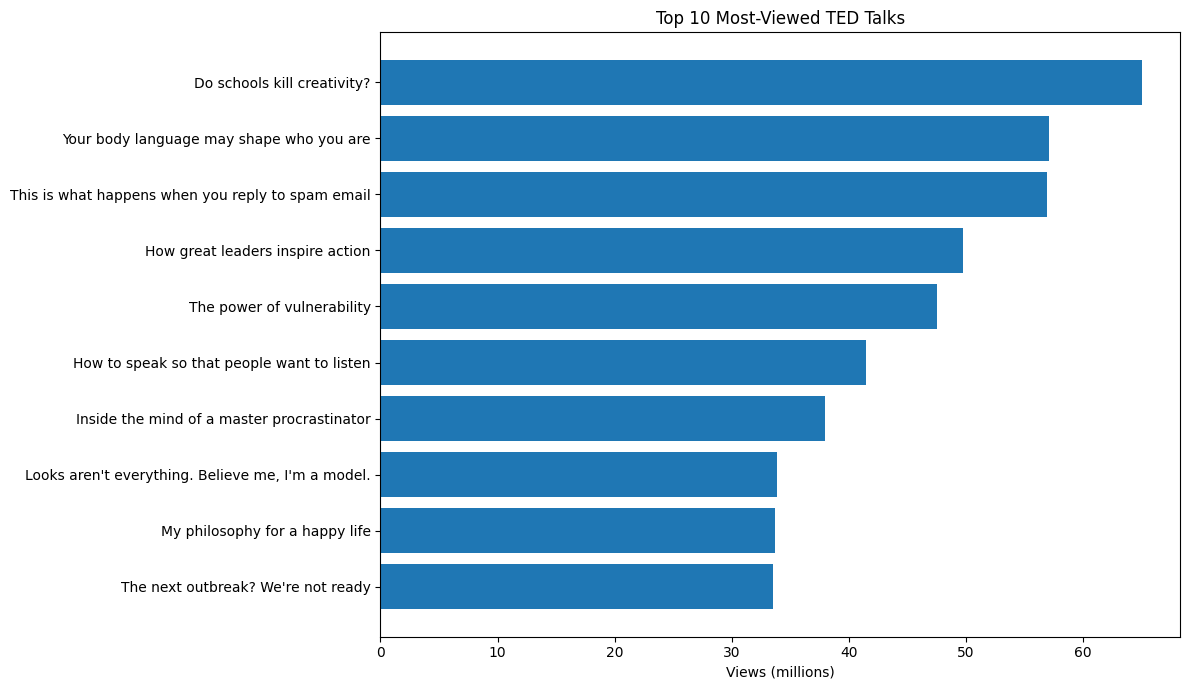

,title,speaker_1,views
1898,The next outbreak? We're not ready,Bill Gates,33521780
2724,My philosophy for a happy life,Sam Berns,33691484
1366,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546
2108,Inside the mind of a master procrastinator,Tim Urban,37976820
1724,How to speak so that people want to listen,Julian Treasure,41504331
796,The power of vulnerability,Brené Brown,47544833
646,How great leaders inspire action,Simon Sinek,49730580
2062,This is what happens when you reply to spam email,James Veitch,56932551
1296,Your body language may shape who you are,Amy Cuddy,57074270
4,Do schools kill creativity?,Sir Ken Robinson,65051954


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

top_talks = ted.nlargest(10, "views").sort_values("views")

plt.figure(figsize=(12, 7))
plt.barh(top_talks["title"], top_talks["views"] / 1_000_000)
plt.xlabel("Views (millions)")
plt.title("Top 10 Most-Viewed TED Talks")
plt.tight_layout()
plt.show()

display(top_talks[["title", "speaker_1", "views"]])


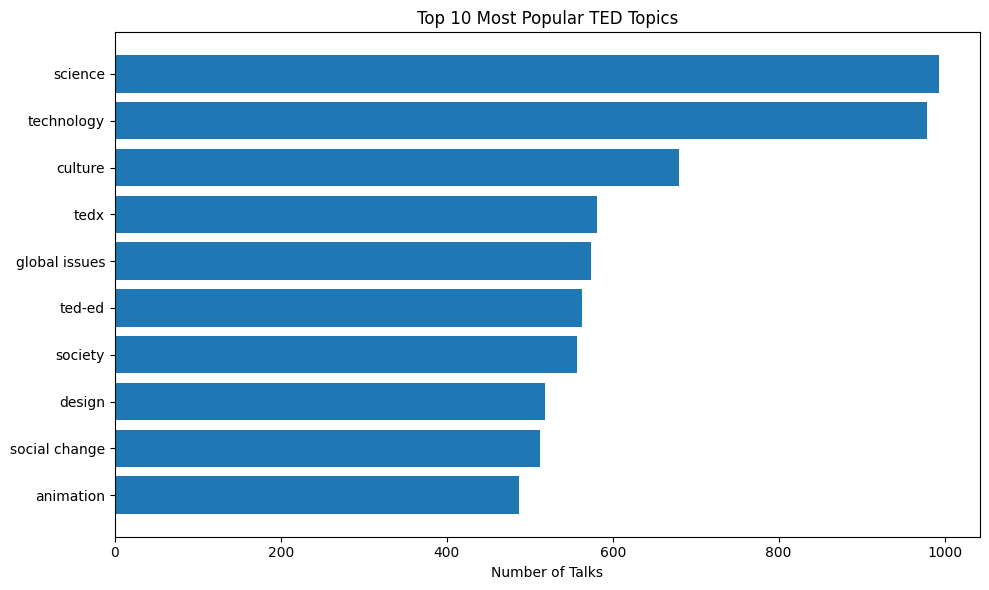

,talk_count
science,993
technology,979
culture,680
tedx,581
global issues,574
ted-ed,563
society,557
design,518
social change,512
animation,487


In [ ]:
from ast import literal_eval
from collections import Counter

def get_topics(value):
    if isinstance(value, list):
        return value
    if isinstance(value, str):
        try:
            result = literal_eval(value)
            if isinstance(result, list):
                return result
        except (ValueError, SyntaxError):
            pass
        return [x.strip() for x in value.split(",") if x.strip()]
    return []

topic_counts = Counter()

for topics in ted["topics"].dropna():
    topic_counts.update(
        str(topic).strip().lower()
        for topic in get_topics(topics)
        if str(topic).strip()
    )

top_topics = pd.Series(dict(topic_counts)).nlargest(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_topics.index, top_topics.values)
plt.xlabel("Number of Talks")
plt.title("Top 10 Most Popular TED Topics")
plt.tight_layout()
plt.show()

display(top_topics.sort_values(ascending=False).rename("talk_count"))

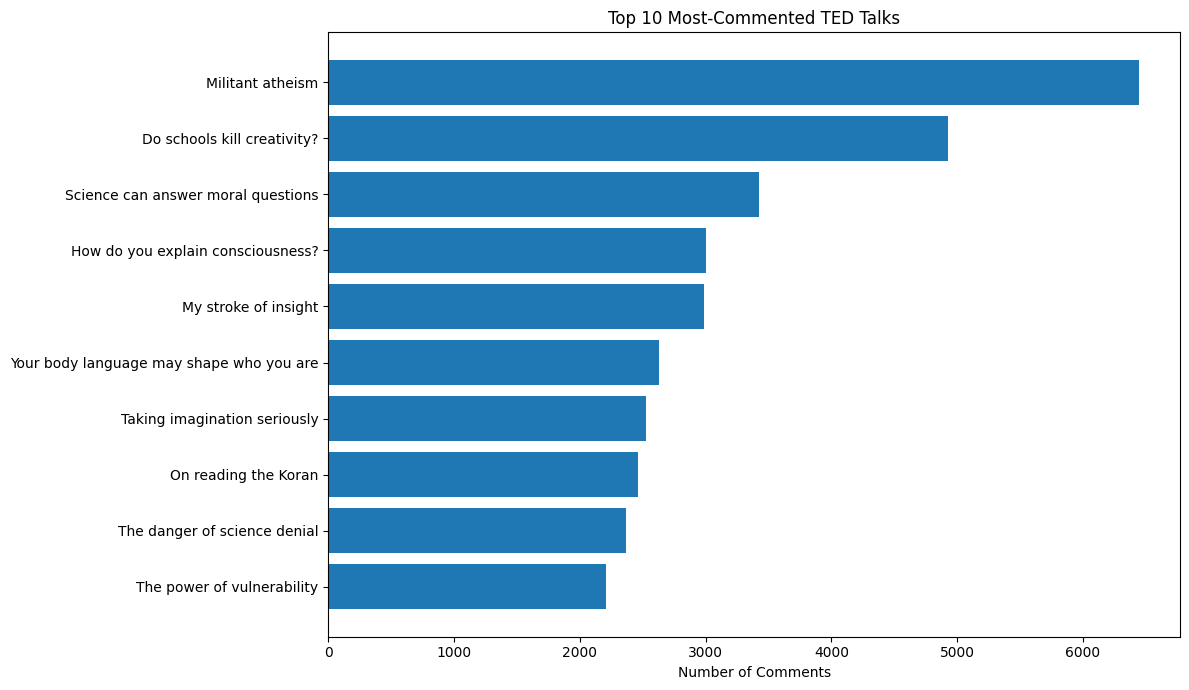

,title,speaker_1,comments
796,The power of vulnerability,Brené Brown,2209.0
631,The danger of science denial,Michael Specter,2366.0
799,On reading the Koran,Lesley Hazleton,2463.0
911,Taking imagination seriously,Janet Echelman,2529.0
1296,Your body language may shape who you are,Amy Cuddy,2633.0
197,My stroke of insight,Jill Bolte Taylor,2984.0
1735,How do you explain consciousness?,David Chalmers,3006.0
617,Science can answer moral questions,Sam Harris,3424.0
4,Do schools kill creativity?,Sir Ken Robinson,4931.0
94,Militant atheism,Richard Dawkins,6449.0


In [ ]:
top_comments = (
    ted.dropna(subset=["comments"])
    .nlargest(10, "comments")
    .sort_values("comments")
)

plt.figure(figsize=(12, 7))
plt.barh(top_comments["title"], top_comments["comments"])
plt.xlabel("Number of Comments")
plt.title("Top 10 Most-Commented TED Talks")
plt.tight_layout()
plt.show()

display(top_comments[["title", "speaker_1", "comments"]])

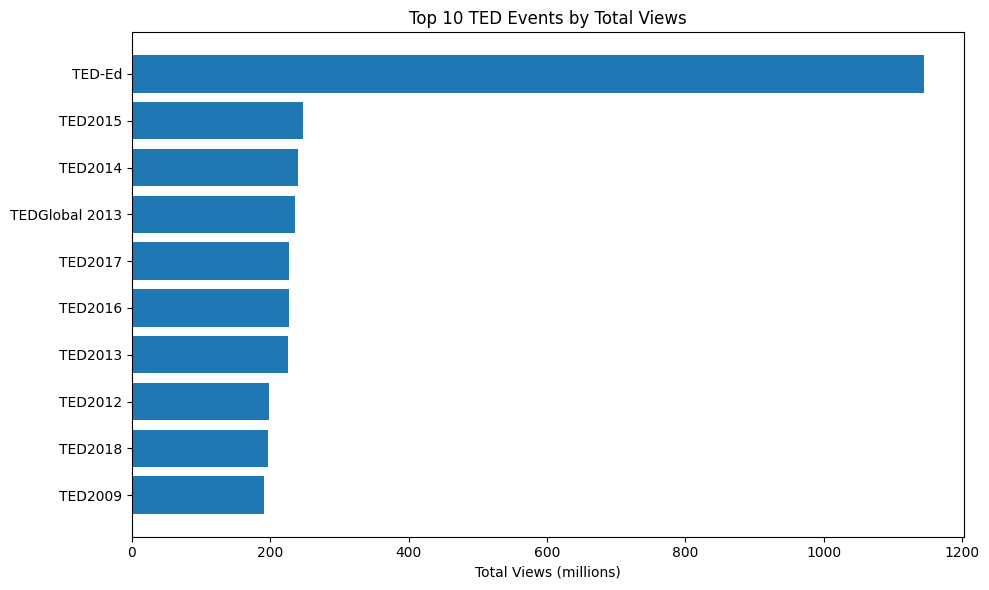

,total_views
event,
TED-Ed,1145357780
TED2015,247702961
TED2014,240295871
TEDGlobal 2013,235410234
TED2017,227847725
TED2016,227358612
TED2013,225967516
TED2012,197746106
TED2018,196346377


In [ ]:
top_events = (
    ted.groupby("event")["views"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(top_events.index, top_events.values / 1_000_000)
plt.xlabel("Total Views (millions)")
plt.title("Top 10 TED Events by Total Views")
plt.tight_layout()
plt.show()

display(top_events.sort_values(ascending=False).rename("total_views"))

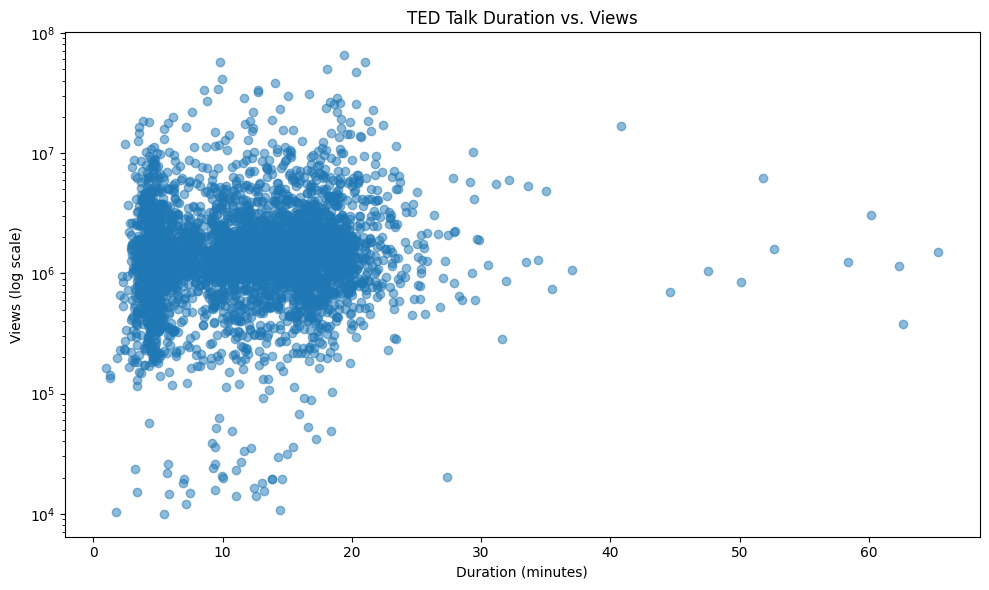

Correlation: 0.07364213656488414


In [ ]:
duration_data = ted.dropna(subset=["duration", "views"]).copy()
duration_data["duration_minutes"] = duration_data["duration"] / 60

plt.figure(figsize=(10, 6))
plt.scatter(
    duration_data["duration_minutes"],
    duration_data["views"],
    alpha=0.5
)
plt.yscale("log")
plt.xlabel("Duration (minutes)")
plt.ylabel("Views (log scale)")
plt.title("TED Talk Duration vs. Views")
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    duration_data["duration_minutes"].corr(duration_data["views"])
)

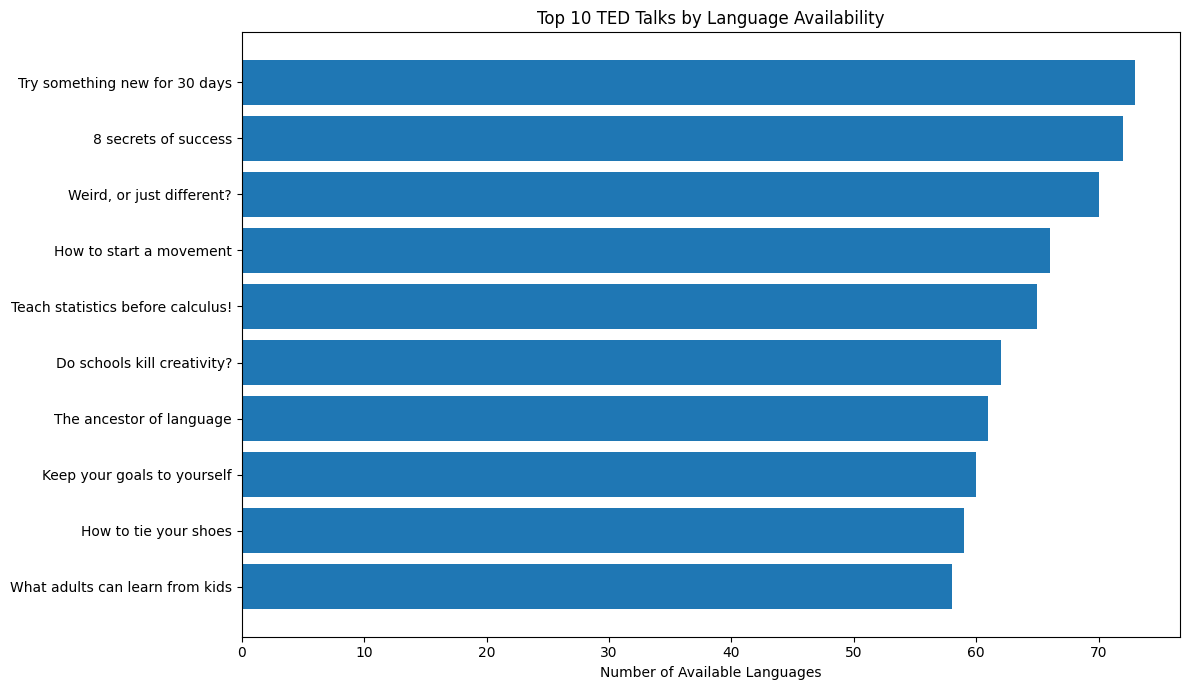

,title,speaker_1,language_count
623,What adults can learn from kids,Adora Svitak,58
899,How to tie your shoes,Terry Moore,59
721,Keep your goals to yourself,Derek Sivers,60
233,The ancestor of language,Murray Gell-Mann,61
4,Do schools kill creativity?,Sir Ken Robinson,62
469,Teach statistics before calculus!,Arthur Benjamin,65
624,How to start a movement,Derek Sivers,66
585,"Weird, or just different?",Derek Sivers,70
48,8 secrets of success,Richard St. John,72
929,Try something new for 30 days,Matt Cutts,73


In [ ]:
def count_languages(value):
    if isinstance(value, list):
        return len(value)
    if isinstance(value, str):
        return len(get_topics(value))
    return 0

ted["language_count"] = ted["available_lang"].apply(count_languages)

top_languages = (
    ted.nlargest(10, "language_count")
    .sort_values("language_count")
)

plt.figure(figsize=(12, 7))
plt.barh(top_languages["title"], top_languages["language_count"])
plt.xlabel("Number of Available Languages")
plt.title("Top 10 TED Talks by Language Availability")
plt.tight_layout()
plt.show()

display(top_languages[["title", "speaker_1", "language_count"]])

In [ ]:
top_talks_langs = ted.nlargest(5, 'language_count')
for idx, row in top_talks_langs.iterrows():
    print(f"Talk: {row['title']}")
    print(f"Calculated Language Count: {row['language_count']}")
    print(f"Raw data sample: {repr(row['available_lang'])[:200]}...")
    print("-" * 50)

Talk: Try something new for 30 days
Calculated Language Count: 73
Raw data sample: "['ar', 'arq', 'az', 'be', 'bg', 'bn', 'bs', 'ca', 'cs', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'eu', 'fa', 'fi', 'fil', 'fr', 'fr-ca', 'gl', 'he', 'hi', 'hr', 'hu', 'hy', 'id', 'it', 'ja', 'ka', '...
--------------------------------------------------
Talk: 8 secrets of success
Calculated Language Count: 72
Raw data sample: "['af', 'am', 'ar', 'arq', 'az', 'bg', 'bn', 'bs', 'ca', 'cs', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'eu', 'fa', 'fil', 'fr', 'fr-ca', 'gu', 'he', 'hi', 'hr', 'hu', 'hy', 'id', 'it', 'ja', 'ka', '...
--------------------------------------------------
Talk: Weird, or just different?
Calculated Language Count: 70
Raw data sample: "['af', 'am', 'ar', 'ast', 'az', 'be', 'bg', 'bn', 'bo', 'bs', 'ca', 'ceb', 'cs', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'fa', 'fi', 'fr', 'fr-ca', 'gl', 'he', 'hi', 'hr', 'hu', 'hy', 'id', 'it', '...
--------------------------------------------------

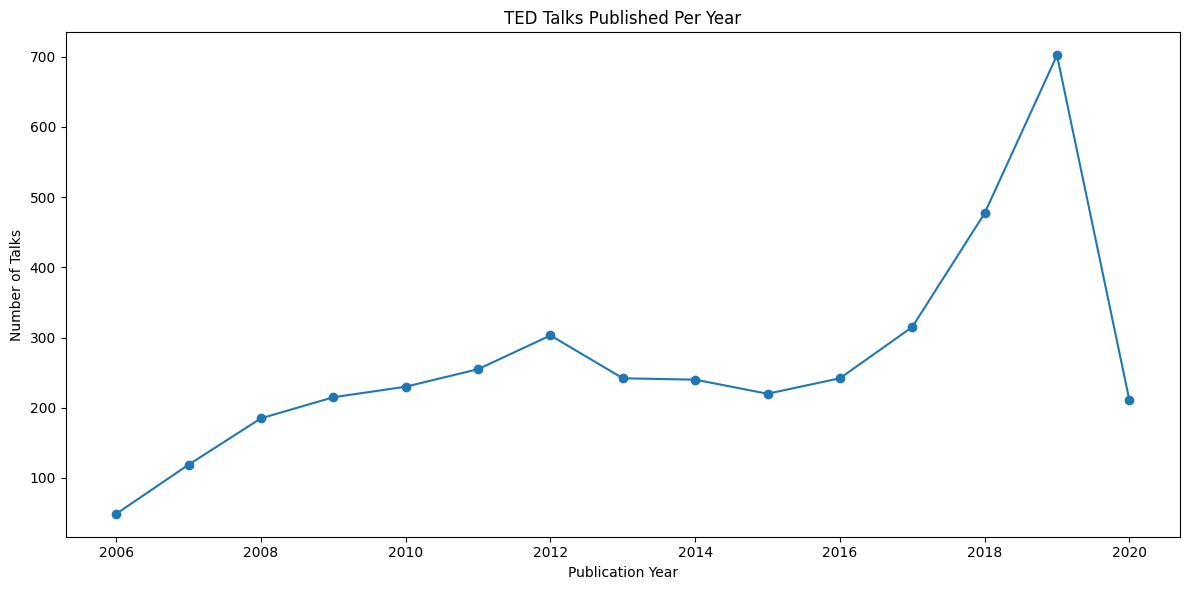

,number_of_talks
published_date,
2006,49
2007,119
2008,185
2009,215
2010,230
2011,255
2012,303
2013,242
2014,240


In [ ]:
ted["published_date"] = pd.to_datetime(
    ted["published_date"], errors="coerce"
)

yearly_talks = (
    ted.dropna(subset=["published_date"])
    .groupby(ted["published_date"].dt.year)
    .size()
)

plt.figure(figsize=(12, 6))
plt.plot(yearly_talks.index, yearly_talks.values, marker="o")
plt.xlabel("Publication Year")
plt.ylabel("Number of Talks")
plt.title("TED Talks Published Per Year")
plt.tight_layout()
plt.show()

display(yearly_talks.rename("number_of_talks"))

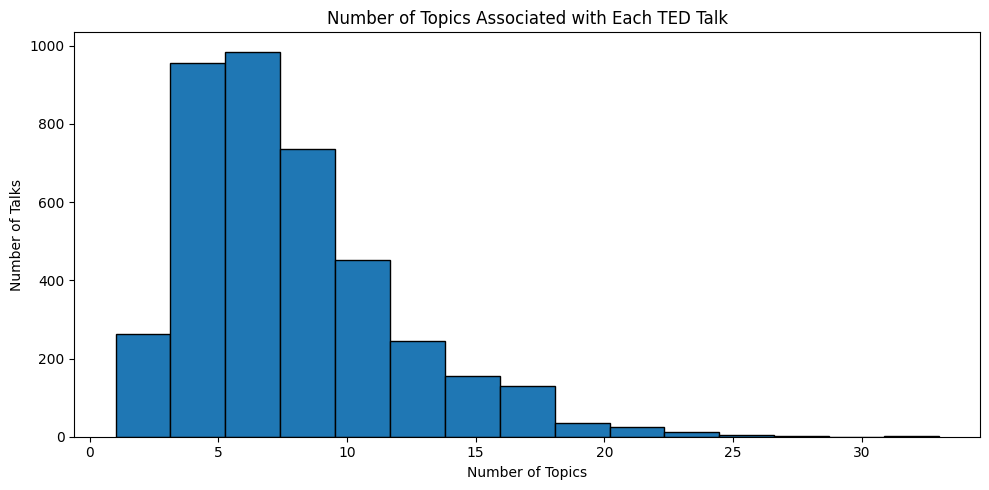

,title,topic_count
0,Averting the climate crisis,9
1,The best stats you've ever seen,11
2,Simplicity sells,9
3,Greening the ghetto,9
4,Do schools kill creativity?,7
5,Behind the design of Seattle's library,5
6,Letting go of God,9
7,Let's teach religion -- all religion -- in sch...,8
8,A life of purpose,8
9,My wish: A global day of film,10


In [ ]:
ted["topic_count"] = ted["topics"].apply(
    lambda x: len(get_topics(x))
)

plt.figure(figsize=(10, 5))
plt.hist(ted["topic_count"], bins=15, edgecolor="black")
plt.xlabel("Number of Topics")
plt.ylabel("Number of Talks")
plt.title("Number of Topics Associated with Each TED Talk")
plt.tight_layout()
plt.show()

display(ted[["title", "topic_count"]].head(10))

In [ ]:
all_speaker_names = set()

for col in ["speaker_1", "all_speakers"]:
    for value in ted[col].dropna():
        if isinstance(value, list):
            names = value
        else:
            names = [name.strip() for name in str(value).split(",")]

        all_speaker_names.update(
            name.strip() for name in names if name.strip()
        )

print("Unique speakers across both columns:", len(all_speaker_names))
print("Unique primary speakers:", ted["speaker_1"].nunique())

Unique speakers across both columns: 6686
Unique primary speakers: 3274


In [ ]:
text_columns = [
    "title",
    "description",
    "transcript",
    "about_speakers"
]

for col in text_columns:
    ted[col + "_word_count"] = (
        ted[col].fillna("").astype(str)
        .str.findall(r"\b\w+\b")
        .str.len()
    )

display(
    ted[[
        "title_word_count",
        "description_word_count",
        "transcript_word_count",
        "about_speakers_word_count"
    ]].describe().round(2)
)

,title_word_count,description_word_count,transcript_word_count,about_speakers_word_count
count,4005.00,4005.00,4005.00,4005.00
mean,6.90,59.11,1845.70,22.87
std,2.46,19.78,1035.63,16.66
min,1.00,9.00,2.00,0.00
25%,5.00,44.00,947.00,15.00
50%,7.00,58.00,1797.00,22.00
75%,8.00,73.00,2510.00,29.00
max,16.00,144.00,11517.00,241.00


In [ ]:
for col in text_columns:
    word_col = col + "_word_count"

    print(f"\n{col.upper()}")
    print("Empty entries:", ted[col].isna().sum() +
          ted[col].fillna("").astype(str).str.strip().eq("").sum()
          - ted[col].isna().sum())
    print("Very short entries (under 10 words):",
          (ted[word_col] < 10).sum())
    print("Unusually long entries (above 99th percentile):",
          (ted[word_col] > ted[word_col].quantile(0.99)).sum())

    display(
        ted.loc[ted[word_col] < 10, ["title", col]]
        .head(5)
    )


TITLE
Empty entries: 0
Very short entries (under 10 words): 3407
Unusually long entries (above 99th percentile): 35


,title,title
0,Averting the climate crisis,Averting the climate crisis
1,The best stats you've ever seen,The best stats you've ever seen
2,Simplicity sells,Simplicity sells
3,Greening the ghetto,Greening the ghetto
4,Do schools kill creativity?,Do schools kill creativity?



DESCRIPTION
Empty entries: 0
Very short entries (under 10 words): 1
Unusually long entries (above 99th percentile): 40


,title,description
84,"Global warming's theme song, ""Manhattan in Jan...","A happy song about global warming, from Jill S..."



TRANSCRIPT
Empty entries: 0
Very short entries (under 10 words): 7
Unusually long entries (above 99th percentile): 41


,title,transcript
145,My magic moves,(Applause) (Music) (Applause)
904,"On violin and cello, ""Passacaglia""",(Music) (Applause) (Music) (Applause)
1198,Dancing with light,(Music) (Applause) (Music) (Applause) (Music) ...
1393,"Dance, tiny robots!",(Mechanical noises) (Music) (Applause)
1825,"A dance in a hurricane of paper, wind and light",(Music) (Applause)



ABOUT_SPEAKERS
Empty entries: 503
Very short entries (under 10 words): 554
Unusually long entries (above 99th percentile): 39


,title,about_speakers
108,Want to help Africa? Do business here,{0: 'Ngozi Okonjo-Iweala is a respected global...
126,Aid versus trade,{0: 'Ngozi Okonjo-Iweala is a respected global...
680,Measuring what makes life worthwhile,{0: 'Chip Conley disrupted the hospitality ind...
698,Why the world needs WikiLeaks,{0: 'Julian Assange serves as spokesperson for...
719,Let the environment guide our development,{0: 'Johan Rockström works to redefine sustain...


Missing transcripts: 0
Empty transcripts: 0
Transcripts under 100 characters: 7


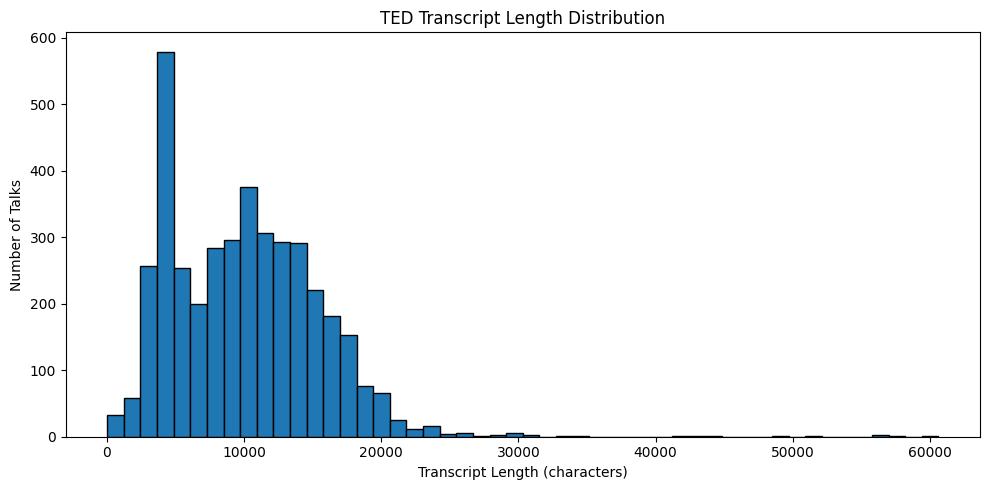

,title,transcript_length
0,Averting the climate crisis,11878
1,The best stats you've ever seen,17453
2,Simplicity sells,18427
3,Greening the ghetto,18305
4,Do schools kill creativity?,17558
5,Behind the design of Seattle's library,18646
6,Letting go of God,15840
7,Let's teach religion -- all religion -- in sch...,20122
8,A life of purpose,18012
9,My wish: A global day of film,21374


In [ ]:
ted["transcript_length"] = (
    ted["transcript"].fillna("").astype(str).str.len()
)

print("Missing transcripts:", ted["transcript"].isna().sum())
print("Empty transcripts:",
      ted["transcript"].fillna("").astype(str).str.strip().eq("").sum())
print("Transcripts under 100 characters:",
      (ted["transcript_length"] < 100).sum())

plt.figure(figsize=(10, 5))
plt.hist(
    ted.loc[ted["transcript_length"] > 0, "transcript_length"],
    bins=50,
    edgecolor="black"
)
plt.xlabel("Transcript Length (characters)")
plt.ylabel("Number of Talks")
plt.title("TED Transcript Length Distribution")
plt.tight_layout()
plt.show()

display(ted[["title", "transcript_length"]].head(10))

In [ ]:
print("Mean views:", ted["views"].mean())
print("Median views:", ted["views"].median())
print("Minimum views:", ted["views"].min())
print("Maximum views:", ted["views"].max())

q1 = ted["views"].quantile(0.25)
q3 = ted["views"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

view_outliers = ted[
    (ted["views"] < lower) | (ted["views"] > upper)
]

print("Potential view outliers:", len(view_outliers))

display(
    view_outliers.nlargest(10, "views")[
        ["title", "speaker_1", "views"]
    ]
)

Mean views: 2148005.5737827714
Median views: 1375508.0
Minimum views: 0
Maximum views: 65051954
Potential view outliers: 393


,title,speaker_1,views
4,Do schools kill creativity?,Sir Ken Robinson,65051954
1296,Your body language may shape who you are,Amy Cuddy,57074270
2062,This is what happens when you reply to spam email,James Veitch,56932551
646,How great leaders inspire action,Simon Sinek,49730580
796,The power of vulnerability,Brené Brown,47544833
1724,How to speak so that people want to listen,Julian Treasure,41504331
2108,Inside the mind of a master procrastinator,Tim Urban,37976820
1366,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546
2724,My philosophy for a happy life,Sam Berns,33691484
1898,The next outbreak? We're not ready,Bill Gates,33521780


Mean duration (minutes): 12.06685393258427
Median duration (minutes): 12.3
Minimum duration (minutes): 1.0
Maximum duration (minutes): 65.36666666666666
Missing or non-numeric durations: 0
Zero or negative durations: 0


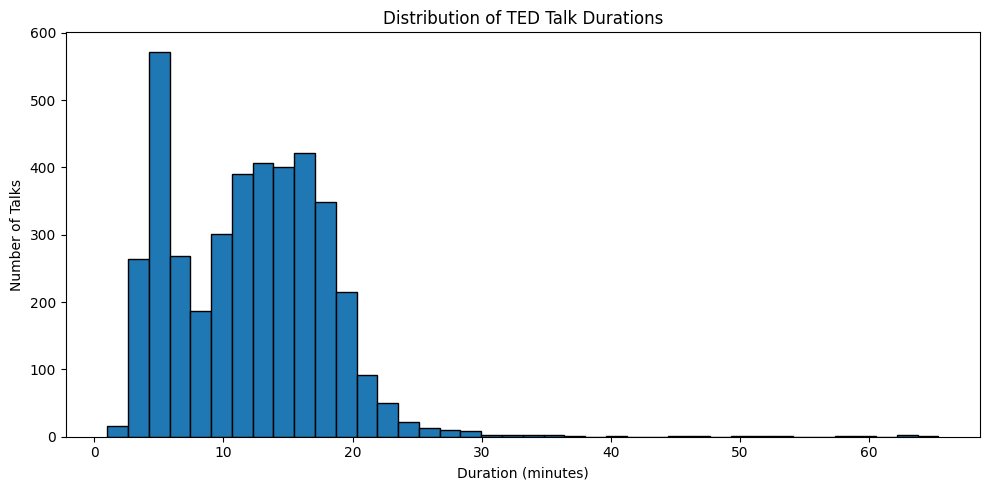

In [ ]:
duration_minutes = pd.to_numeric(
    ted["duration"], errors="coerce"
) / 60

print("Mean duration (minutes):", duration_minutes.mean())
print("Median duration (minutes):", duration_minutes.median())
print("Minimum duration (minutes):", duration_minutes.min())
print("Maximum duration (minutes):", duration_minutes.max())
print("Missing or non-numeric durations:",
      duration_minutes.isna().sum())
print("Zero or negative durations:",
      (duration_minutes <= 0).sum())

plt.figure(figsize=(10, 5))
plt.hist(
    duration_minutes[duration_minutes > 0].dropna(),
    bins=40,
    edgecolor="black"
)
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Talks")
plt.title("Distribution of TED Talk Durations")
plt.tight_layout()
plt.show()

In [ ]:
for col in ["recorded_date", "published_date"]:
    ted[col] = pd.to_datetime(ted[col], errors="coerce")

    print(f"\n{col}")
    print("Earliest:", ted[col].min())
    print("Latest:", ted[col].max())
    print("Missing or invalid dates:", ted[col].isna().sum())


recorded_date
Earliest: 1984-02-02 00:00:00
Latest: 2020-04-30 00:00:00
Missing or invalid dates: 1

published_date
Earliest: 2006-06-27 00:00:00
Latest: 2020-04-30 00:00:00
Missing or invalid dates: 0


Missing native language: 0
Missing available languages: 0


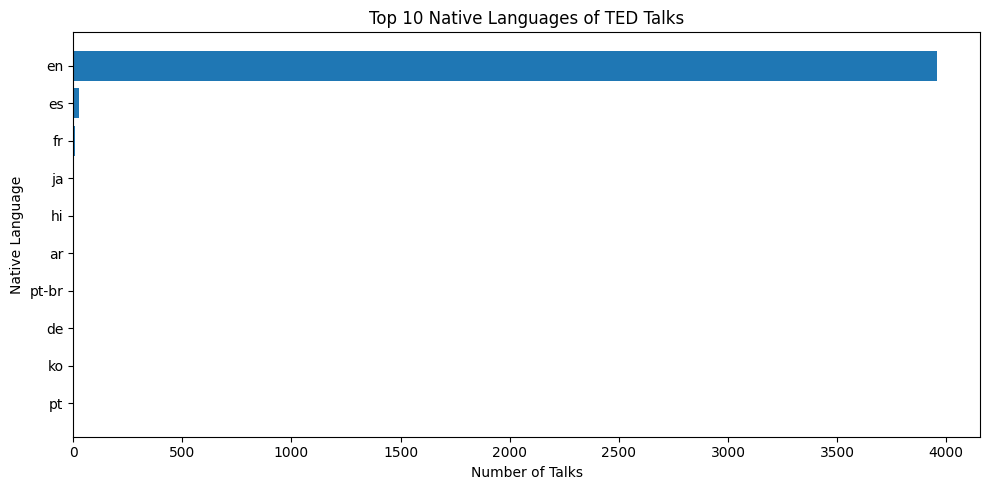

,available_lang
0,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
1,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de..."
2,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr..."
3,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es..."
4,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs..."
5,"['ar', 'bg', 'en', 'es', 'fr', 'he', 'it', 'ja..."
6,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
7,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
8,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa..."
9,"['ar', 'bg', 'cs', 'en', 'es', 'fa', 'fr', 'he..."


In [ ]:
print("Missing native language:", ted["native_lang"].isna().sum())
print("Missing available languages:", ted["available_lang"].isna().sum())

native_counts = ted["native_lang"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 5))
plt.barh(native_counts.index, native_counts.values)
plt.xlabel("Number of Talks")
plt.ylabel("Native Language")
plt.title("Top 10 Native Languages of TED Talks")
plt.tight_layout()
plt.show()

display(ted["available_lang"].dropna().head(10))

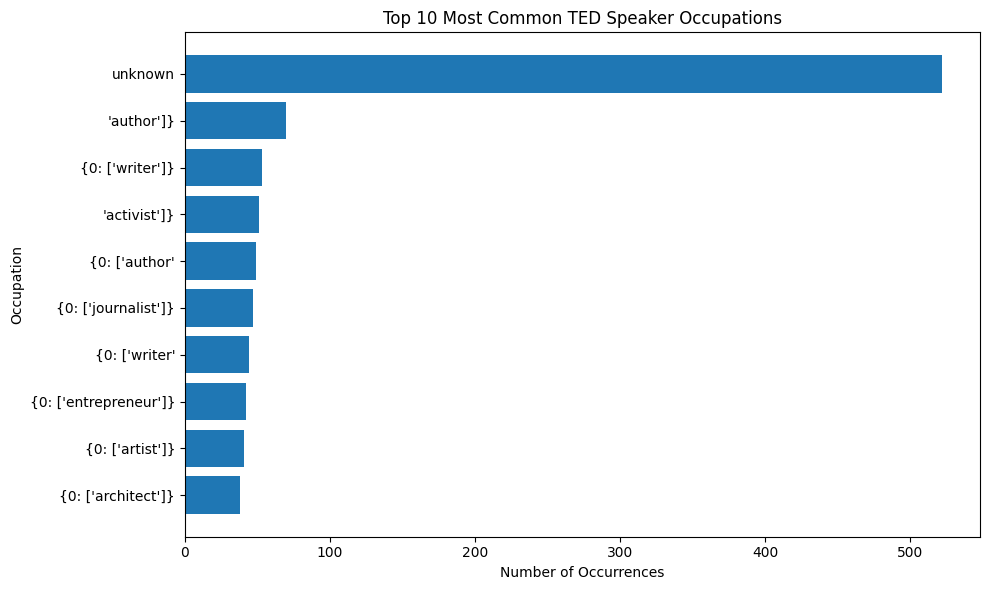

,0
unknown,522
'author']},70
{0: ['writer']},53
'activist']},51
{0: ['author',49
{0: ['journalist']},47
{0: ['writer',44
{0: ['entrepreneur']},42
{0: ['artist']},41
{0: ['architect']},38


In [ ]:
occupation_counts = Counter()

for value in ted["occupations"].dropna():
    occupation_counts.update(
        str(item).strip().lower()
        for item in get_topics(value)
        if str(item).strip()
    )

top_occupations = pd.Series(dict(occupation_counts)).nlargest(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_occupations.index, top_occupations.values)
plt.xlabel("Number of Occurrences")
plt.ylabel("Occupation")
plt.title("Top 10 Most Common TED Speaker Occupations")
plt.tight_layout()
plt.show()

display(top_occupations.sort_values(ascending=False))